# Exploratory Data Analysis — Kiva Microloans
**Name:** Priyal Rana  **Roll No:** DM281052  **Programme:** PGDM 2026–28, GLIM Chennai

**Primary column:** `loan_amount` (USD)

---
> 🗒️ **How to use this notebook (delete this box before submitting)**
> 1. Open it in Google Colab (File → Upload notebook).
> 2. Click the 📁 folder icon on the left and upload `kiva_loans.zip`. Wait for the upload to finish.
> 3. Click **Runtime → Run all**. Everything runs top to bottom in about 2–3 minutes.
> 4. Every grey ✍️ box is where *you* write. Read the chart and numbers above it, fill in the four bullets, then delete the grey box.
> 5. Before submitting, do **Runtime → Restart session and run all** so all outputs are fresh, then **File → Download → .ipynb**.

In [1]:
# ---- Setup: load the libraries we need ----
import numpy as np                  # maths on arrays of numbers
import pandas as pd                 # tables (DataFrames): load, clean, summarise data
import matplotlib.pyplot as plt     # basic plotting
import seaborn as sns               # nicer statistical charts on top of matplotlib
from scipy import stats             # statistical tests (correlation, t-test, ANOVA, chi-square)
import warnings
warnings.filterwarnings("ignore")   # hide harmless library warnings so the output stays clean

pd.set_option("display.max_columns", 50)                    # show all columns when printing a table
pd.set_option("display.float_format", "{:,.2f}".format)     # print numbers with commas and 2 decimals

# One consistent colour palette for every chart (colour-blind-safe order)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE = PALETTE[0]
sns.set_theme(style="whitegrid", palette=PALETTE,
              rc={"axes.titleweight": "bold", "axes.titlesize": 13,
                  "grid.color": "#e6e6e3", "axes.edgecolor": "#bdbdb8", "figure.dpi": 100})

RANDOM_STATE = 42   # fixed seed so random samples are the same every time the notebook is run

In [2]:
# ---- Load the data ----
# pandas can read the CSV directly from inside the zip file
DATA_FILE = "kiva_loans.zip"      # change to "kiva_loans.csv" if you uploaded the unzipped file
df_raw = pd.read_csv(DATA_FILE)
print("Loaded:", df_raw.shape[0], "rows x", df_raw.shape[1], "columns")

Loaded: 671205 rows x 20 columns


# Section A — Dataset understanding and primary column

### A1. Context

> ✍️ *Edit into your own words.*

- **Dataset:** Data Science for Good: Kiva Crowdfunding — file `kiva_loans.csv`
- **Link:** https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding
- **Source organisation:** Kiva Microfunds (a US non-profit), published on Kaggle by Kiva
- **Time period:** loans posted between January 2014 and July 2017
- **Real-world process:** A borrower in a developing country applies for a small loan through a local microfinance institution (Kiva's "field partner"). The loan is posted on Kiva's website, where individual lenders around the world chip in as little as \$25 each until the loan is fully funded.
- **One row =** one microloan posted on Kiva.

### A2. Business problem

> ✍️ *Edit into your own words.*

**Business question:** What determines how large a microloan is — the sector, the borrower's gender, the repayment structure, the loan term or the country?

**Decision-maker:** The head of loan products at a microfinance institution (a Kiva field partner). They decide which loan sizes and repayment schedules to offer to which borrower segments, and how much crowdfunding support each loan will need.

### A3. Data dictionary

| Column | Plain-English meaning | pandas dtype | Classification | Example |
|---|---|---|---|---|
| `id` | Unique loan ID | int64 | ID | 653051 |
| `funded_amount` | Amount actually raised from lenders (USD) | float64 | Numeric continuous | 300.0 |
| `loan_amount` | Amount the borrower asked for (USD) — **primary column** | float64 | Numeric continuous | 300.0 |
| `activity` | Detailed business activity (163 types) | object | Categorical nominal | Fruits & Vegetables |
| `sector` | Broad sector of the loan (15 levels) | object | Categorical nominal | Food |
| `use` | Free-text description of what the loan is for | object | Text | To buy seasonal, fresh fruits to sell. |
| `country_code` | 2-letter country code | object | Categorical nominal | PK |
| `country` | Borrower's country (87 levels) | object | Categorical nominal | Pakistan |
| `region` | Town / region within the country | object | Categorical nominal (very many levels) | Lahore |
| `currency` | Currency the loan is disbursed in | object | Categorical nominal | PKR |
| `partner_id` | ID of the microfinance field partner | float64 | ID | 247.0 |
| `posted_time` | When the loan was posted on Kiva | object (should be datetime) | Date | 2014-01-01 06:12:39+00:00 |
| `disbursed_time` | When the money was given to the borrower | object (should be datetime) | Date | 2013-12-17 08:00:00+00:00 |
| `funded_time` | When the loan became fully funded | object (should be datetime) | Date | 2014-01-02 10:06:32+00:00 |
| `term_in_months` | Repayment period of the loan | float64 | Numeric discrete | 12.0 |
| `lender_count` | Number of lenders who contributed | int64 | Numeric discrete | 12 |
| `tags` | Hashtags added by Kiva users | object | Text | #Woman Owned Biz |
| `borrower_genders` | Gender of each borrower in the group (comma-separated) | object | Text → to be cleaned into categorical | female, female, male |
| `repayment_interval` | How the loan is repaid (4 levels) | object | Categorical nominal | monthly |
| `date` | Posting date (date only) | object (should be datetime) | Date | 2014-01-01 |

In [3]:
print("Shape (rows, columns):", df_raw.shape)

Shape (rows, columns): (671205, 20)


In [4]:
df_raw.info()   # column names, data types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 671205 entries, 0 to 671204
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  671205 non-null  int64  
 1   funded_amount       671205 non-null  float64
 2   loan_amount         671205 non-null  float64
 3   activity            671205 non-null  str    
 4   sector              671205 non-null  str    
 5   use                 666973 non-null  str    
 6   country_code        671197 non-null  str    
 7   country             671205 non-null  str    
 8   region              614405 non-null  str    
 9   currency            671205 non-null  str    
 10  partner_id          657698 non-null  float64
 11  posted_time         671205 non-null  str    
 12  disbursed_time      668809 non-null  str    
 13  funded_time         622874 non-null  str    
 14  term_in_months      671205 non-null  float64
 15  lender_count        671205 non-null  int64  


In [5]:
df_raw.head()   # first five rows

,id,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,653051,300.00,300.00,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,247.00,2014-01-01 06:12:39+00:00,2013-12-17 08:00:00+00:00,2014-01-02 10:06:32+00:00,12.00,12,NaN,female,irregular,2014-01-01
1,653053,575.00,575.00,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,247.00,2014-01-01 06:51:08+00:00,2013-12-17 08:00:00+00:00,2014-01-02 09:17:23+00:00,11.00,14,NaN,"female, female",irregular,2014-01-01
2,653068,150.00,150.00,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,334.00,2014-01-01 09:58:07+00:00,2013-12-17 08:00:00+00:00,2014-01-01 16:01:36+00:00,43.00,6,"user_favorite, user_favorite",female,bullet,2014-01-01
3,653063,200.00,200.00,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,247.00,2014-01-01 08:03:11+00:00,2013-12-24 08:00:00+00:00,2014-01-01 13:00:00+00:00,11.00,8,NaN,female,irregular,2014-01-01
4,653084,400.00,400.00,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,245.00,2014-01-01 11:53:19+00:00,2013-12-17 08:00:00+00:00,2014-01-01 19:18:51+00:00,14.00,16,NaN,female,monthly,2014-01-01


### A4. Primary column

> ✍️ *Edit into your own words.*

**Primary column: `loan_amount`** — the amount (USD) the borrower requested. It is **numeric (continuous)**.

**Why it matters:** Loan size is the core product decision for a microfinance institution. Too small and the borrower cannot grow their business; too large and repayment risk rises and the loan needs many more lenders to fund it on Kiva. Knowing which segments take larger or smaller loans helps the product head design loan sizes and repayment schedules for each segment.

### A5. Supporting columns and expectations

> ✍️ *These are suggested expectations — change any you disagree with. It is fine (even good) if the data later rejects some of them.*

| # | Supporting column | Type | Expectation |
|---|---|---|---|
| E1 | `sector` | Categorical | Retail and Services loans are larger than Agriculture and Personal Use loans. |
| E2 | `gender_group` (cleaned from `borrower_genders`) | Categorical | Loans to women are smaller than loans to men. |
| E3 | `repayment_interval` | Categorical | Bullet (single lump-sum) loans are larger than monthly loans. |
| E4 | `term_in_months` | Numeric | Longer-term loans are larger loans. |
| E5 | `lender_count` | Numeric | Larger loans need more lenders (strong positive link). |
| E6 | `days_to_fund` (created) | Numeric | Larger loans take longer to get fully funded. |
| E7 | `country_group` (top 10 countries + Other) | Categorical | Loan sizes differ a lot between countries (e.g. Latin America larger than South-East Asia). |

**Columns to drop and why:**
- `id`, `partner_id` — identifiers, no analytical meaning.
- `use`, `tags` — free text.
- `activity` — 163 levels, too many for charts; `sector` already summarises it.
- `region` — thousands of levels and 8% missing.
- `country_code`, `currency` — duplicate the information in `country`.
- `disbursed_time`, `date`, `posted_time`, `funded_time` — replaced by the created columns `posted_year` and `days_to_fund`.
- **Leakage note:** `funded_amount` is almost identical to `loan_amount` (it is an *outcome* of crowdfunding the loan), so it is not used as a driver. It is used only to create `fully_funded`.

# Section B — Data preprocessing

### B1. Initial quality audit
**Question:** How big is the data, what types are the columns, are there duplicates, and which columns have missing values? Is the missingness random or tied to a group?

In [6]:
print("Rows:", df_raw.shape[0], "| Columns:", df_raw.shape[1])
print("\nData types:\n", df_raw.dtypes.value_counts())
print("\nFully duplicated rows:", df_raw.duplicated().sum())
print("Duplicated loan IDs:", df_raw["id"].duplicated().sum())

# Missing values per column: count and %
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
missing

Rows: 671205 | Columns: 20

Data types:
 str        14
float64     4
int64       2
Name: count, dtype: int64



Fully duplicated rows: 0
Duplicated loan IDs: 0


,missing_count,missing_%
tags,171416,25.54
region,56800,8.46
funded_time,48331,7.20
partner_id,13507,2.01
use,4232,0.63
borrower_genders,4221,0.63
disbursed_time,2396,0.36
country_code,8,0.00
activity,0,0.00
loan_amount,0,0.00


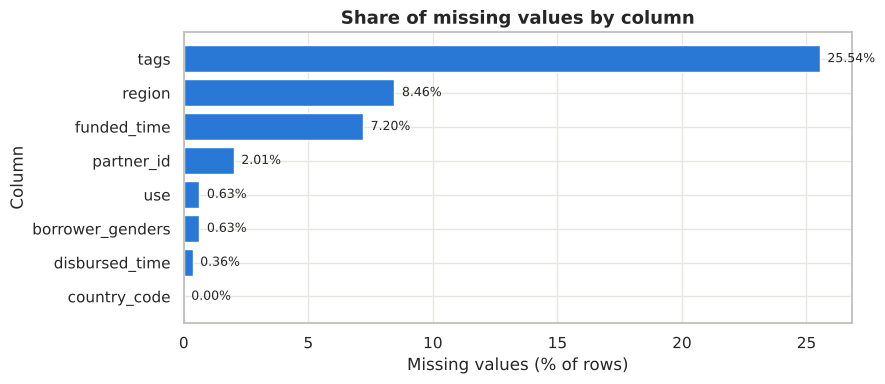

In [7]:
# Bar chart of % missing, only for columns that have missing values
miss_plot = missing[missing["missing_count"] > 0]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(miss_plot.index, miss_plot["missing_%"], color=BLUE)
ax.invert_yaxis()                                   # largest bar on top
for i, v in enumerate(miss_plot["missing_%"]):      # write the % next to each bar
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center", fontsize=9)
ax.set_title("Share of missing values by column")
ax.set_xlabel("Missing values (% of rows)")
ax.set_ylabel("Column")
plt.tight_layout(); plt.show()

In [8]:
# Is missingness random or tied to a group?
# (1) funded_time is blank -> was the loan fully funded?
fully_funded_flag = df_raw["funded_amount"] >= df_raw["loan_amount"]
print("Loans with missing funded_time, split by whether they were fully funded:")
print(pd.crosstab(df_raw["funded_time"].isna(), fully_funded_flag,
                  rownames=["funded_time missing"], colnames=["fully funded"]))

# (2) Which countries have the most missing region values?
print("\nShare of rows with missing region, top 8 countries:")
print((df_raw["region"].isna().groupby(df_raw["country"]).mean() * 100)
      .sort_values(ascending=False).head(8).round(1))

# (3) Missing country_code: which country?
print("\nRows with missing country_code by country:")
print(df_raw.loc[df_raw["country_code"].isna(), "country"].value_counts())

Loans with missing funded_time, split by whether they were fully funded:
fully funded         False   True 
funded_time missing               
False                    0  622874
True                 48328       3

Share of rows with missing region, top 8 countries:
country
Kosovo           100.00
Iraq             100.00
Virgin Islands   100.00
Puerto Rico      100.00
Guam             100.00
Benin             99.60
Turkey            99.10
Senegal           98.80
Name: region, dtype: float64

Rows with missing country_code by country:
country
Namibia    8
Name: count, dtype: int64


**Insight — B1: data quality audit**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Which column has the most missing values (count and %)?
> - funded_time is missing almost only for loans that were NOT fully funded — so it is not random, it is *structural*.
> - country_code is missing only for Namibia. Namibia's code is 'NA', which pandas reads as 'missing'! That is a data-reading error, not real missing data.
> - Is region missingness concentrated in a few countries?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### B2. Missing value treatment
**Question:** How should each column with missing values be treated, and why?

| Column | Missing | Treatment | Reason |
|---|---|---|---|
| `tags` | 25.5% | Drop column | Free text, not needed for the business question |
| `region` | 8.5% | Drop column | Thousands of levels; `country` covers location |
| `funded_time` | 7.2% | **Keep as missing** (no imputation) | Missing because the loan never got fully funded — imputing would invent a date. Used to create `fully_funded` and `days_to_fund` |
| `partner_id` | 2.0% | Drop column | ID column |
| `use` | 0.6% | Drop column | Free text |
| `borrower_genders` | 0.6% | **New "Unknown" category** | Gender cannot be guessed; dropping would lose loans with valid loan amounts |
| `disbursed_time` | 0.4% | Drop column | Not needed |
| `country_code` | 8 rows | Fix to "NA" (Namibia) | Reading error, not real missing data (done in B3) |

In [9]:
df = df_raw.copy()   # work on a copy so the raw data stays untouched
before = df.isna().sum()

# 1) Drop columns that are IDs, free text or not needed (see A5)
df = df.drop(columns=["tags", "region", "partner_id", "use", "disbursed_time"])

# 2) borrower_genders: fill missing with "Unknown" (it becomes its own category later in B3)
df["borrower_genders"] = df["borrower_genders"].fillna("Unknown")

# 3) country_code: Namibia's code "NA" was read as missing -> put it back
df.loc[df["country"] == "Namibia", "country_code"] = "NA"

# 4) funded_time: deliberately left missing (loan never fully funded)

after = df.isna().sum()
pd.DataFrame({"missing_before": before,
              "missing_after": [str(int(after[c])) if c in after.index else "column dropped" for c in before.index]})

,missing_before,missing_after
id,0,0
funded_amount,0,0
loan_amount,0,0
activity,0,0
sector,0,0
use,4232,column dropped
country_code,8,0
country,0,0
region,56800,column dropped
currency,0,0


**Insight — B2: missing value treatment**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - How many missing values were there before vs after?
> - Why is leaving funded_time blank better than filling it with an average date?
> - Why a separate 'Unknown' gender category instead of dropping 4,221 rows?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### B3. Duplicates and inconsistencies
**Question:** Are there duplicate rows, messy categories, wrong data types or impossible values?

In [10]:
# --- Duplicates ---
n_before = len(df)
df = df.drop_duplicates()
print("Duplicate rows removed:", n_before - len(df))

# --- Messy text categories: remove extra spaces and fix capitalisation ---
for col in ["sector", "country", "repayment_interval", "activity"]:
    before_levels = df[col].nunique()
    df[col] = df[col].str.strip()                       # remove leading/trailing spaces
    if col == "repayment_interval":
        df[col] = df[col].str.lower()                   # e.g. 'Monthly ' -> 'monthly'
    print(f"{col}: {before_levels} levels before, {df[col].nunique()} after cleaning")

Duplicate rows removed: 0
sector: 15 levels before, 15 after cleaning
country: 87 levels before, 87 after cleaning


repayment_interval: 4 levels before, 4 after cleaning
activity: 163 levels before, 163 after cleaning


In [11]:
# --- borrower_genders is messy: one cell can hold many borrowers, e.g. "female, female, male" ---
print("Most common raw values:")
print(df["borrower_genders"].value_counts().head(6))
print("Number of distinct raw values:", df["borrower_genders"].nunique())

def gender_group(text):
    """Turn 'female, female, male' into one clean label."""
    if text == "Unknown":
        return "Unknown"
    people = set(g.strip() for g in text.split(","))   # unique genders in the group
    if people == {"female"}:
        return "Female"
    if people == {"male"}:
        return "Male"
    return "Mixed group"

df["gender_group"] = df["borrower_genders"].apply(gender_group)
# Number of borrowers = number of comma-separated entries (missing -> NaN)
df["borrower_count"] = np.where(df["borrower_genders"] == "Unknown", np.nan,
                                df["borrower_genders"].str.count(",") + 1)

print("\nAfter cleaning, gender_group levels:")
print(df["gender_group"].value_counts())

Most common raw values:
borrower_genders
female                                    426502
male                                      134710
female, female                             12164
female, female, female                     11676
female, female, female, female              9052
female, female, female, female, female      7568
Name: count, dtype: int64
Number of distinct raw values: 11299



After cleaning, gender_group levels:
gender_group
Female         488081
Male           138523
Mixed group     40380
Unknown          4221
Name: count, dtype: int64


In [12]:
# --- Wrong data types: dates are stored as text -> convert to real dates ---
for col in ["posted_time", "funded_time"]:
    df[col] = pd.to_datetime(df[col])
print(df[["posted_time", "funded_time"]].dtypes)

# --- Impossible values ---
# (a) funded more than the amount asked for
over_funded = df["funded_amount"] > df["loan_amount"]
print("\nLoans funded MORE than requested (impossible):", over_funded.sum())
# (b) fully funded BEFORE it was posted (negative time)
days = (df["funded_time"] - df["posted_time"]).dt.total_seconds() / 86400
print("Loans funded before they were posted (negative days):", (days < 0).sum())
# (c) zero or negative amounts / terms
print("Loans with loan_amount <= 0:", (df["loan_amount"] <= 0).sum())
print("Loans with term_in_months <= 0:", (df["term_in_months"] <= 0).sum())

# Treatment: drop the over-funded rows; set negative funding time to missing
df = df[~over_funded].copy()
days = days[~over_funded]
days[days < 0] = np.nan

posted_time    datetime64[us, UTC]
funded_time    datetime64[us, UTC]
dtype: object



Loans funded MORE than requested (impossible): 2
Loans funded before they were posted (negative days): 1
Loans with loan_amount <= 0: 0
Loans with term_in_months <= 0: 0


In [13]:
# --- Create the new columns used in the analysis ---
df["days_to_fund"] = days                                        # how long it took to get fully funded
df["fully_funded"] = np.where(df["funded_amount"] >= df["loan_amount"], "Yes", "No")
df["posted_year"] = df["posted_time"].dt.year

# Country has 87 levels -> keep the 10 biggest and group the rest as "Other"
top10 = df["country"].value_counts().head(10).index
df["country_group"] = np.where(df["country"].isin(top10), df["country"], "Other")

# Loan size bands (based on the quartiles of loan_amount) for cross-tabs
df["loan_band"] = pd.cut(df["loan_amount"], bins=[0, 275, 1000, np.inf],
                         labels=["Small (≤$275)", "Medium ($276–1,000)", "Large (>$1,000)"])

# Drop the raw columns that have now been replaced
df = df.drop(columns=["id", "activity", "country_code", "currency", "date",
                      "borrower_genders", "posted_time", "funded_time"])
print("Columns now:", list(df.columns))

Columns now: ['funded_amount', 'loan_amount', 'sector', 'country', 'term_in_months', 'lender_count', 'repayment_interval', 'gender_group', 'borrower_count', 'days_to_fund', 'fully_funded', 'posted_year', 'country_group', 'loan_band']


**Insight — B3: duplicates and inconsistencies**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Were there any duplicates? (Say so clearly even if the answer is zero.)
> - How many distinct raw values did borrower_genders have, and how many clean groups now?
> - Which impossible values did you find, how many, and what did you do with them?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### B4. Outlier detection
**Question:** Which key numeric columns have outliers by the IQR rule, how many rows are flagged, and should they be kept?

In [14]:
def iqr_outliers(s):
    """Return the IQR fences and the number of outliers for a numeric column."""
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # standard IQR rule
    n_out = ((s < low) | (s > high)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": low, "upper_fence": high,
                      "outliers": n_out, "outliers_%": n_out / len(s) * 100})

num_cols = ["loan_amount", "term_in_months", "lender_count", "days_to_fund"]
outlier_table = pd.DataFrame({c: iqr_outliers(df[c]) for c in num_cols}).T
outlier_table

,Q1,Q3,IQR,lower_fence,upper_fence,outliers,outliers_%
loan_amount,275.00,"1,000.00",725.00,-812.50,"2,087.50","50,992.00",7.60
term_in_months,8.00,14.00,6.00,-1.00,23.00,"65,780.00",9.80
lender_count,7.00,24.00,17.00,-18.50,49.50,"54,127.00",8.06
days_to_fund,5.17,22.54,17.36,-20.87,48.59,"7,041.00",1.13


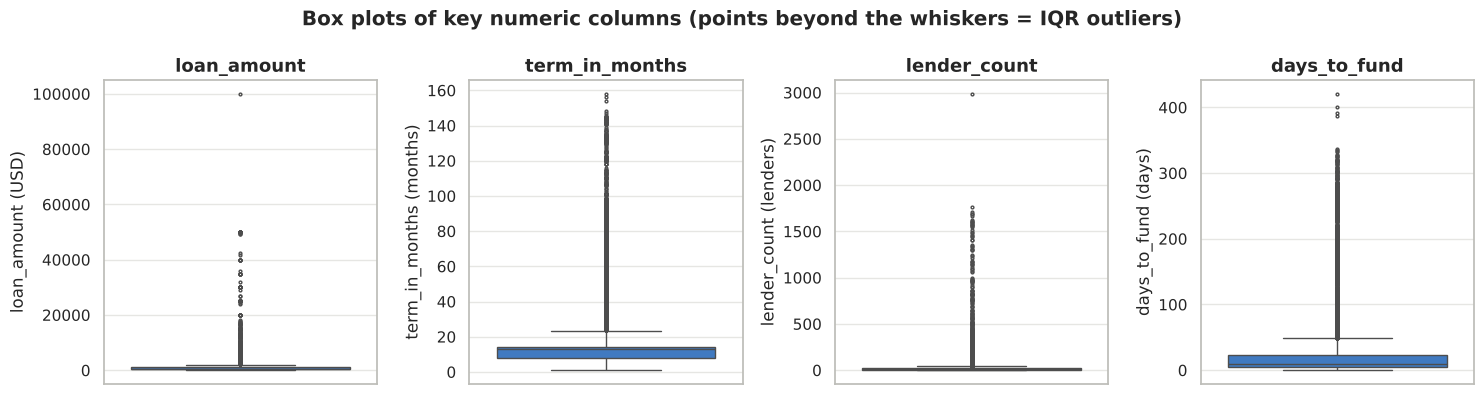

,loan_amount,sector,country,gender_group,borrower_count,lender_count
70499,"100,000.00",Agriculture,Haiti,Female,1.00,2986
34196,"50,000.00",Retail,Peru,Male,1.00,1446
43182,"50,000.00",Retail,Kenya,Male,1.00,1491
53634,"50,000.00",Retail,Uganda,Female,1.00,1581
126839,"50,000.00",Agriculture,Mexico,Mixed group,8.00,586


In [15]:
units = {"loan_amount": "USD", "term_in_months": "months", "lender_count": "lenders", "days_to_fund": "days"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color=BLUE, fliersize=2)
    ax.set_title(col)
    ax.set_ylabel(f"{col} ({units[col]})")
fig.suptitle("Box plots of key numeric columns (points beyond the whiskers = IQR outliers)", fontweight="bold")
plt.tight_layout(); plt.show()

# Look at the most extreme loans to judge if they are genuine
df.nlargest(5, "loan_amount")[["loan_amount", "sector", "country", "gender_group", "borrower_count", "lender_count"]]

**Treatment decision:** The outliers are **kept**. The largest loans (up to \$100,000) are genuine — they are mostly large group or cooperative loans with thousands of lenders, not typing errors. Removing them would hide exactly the segment the product head cares about. To stop them squashing the charts, later charts use a **log scale** for `loan_amount`.

> ✍️ *Reword this decision in your own words if you agree, or change it if you prefer to cap the values.*

**Insight — B4: outliers**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Which column has the most outliers, as count and %?
> - Why is loan_amount's upper fence so low compared with its maximum?
> - Do the biggest loans look genuine (look at borrower_count and lender_count)?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### B6. Final clean dataset summary
**Question:** What does the clean dataset look like, and how much of the original data was kept?

In [16]:
print("Final shape:", df.shape)
df.describe()

Final shape: (671203, 14)


,funded_amount,loan_amount,term_in_months,lender_count,borrower_count,days_to_fund,posted_year
count,"671,203.00","671,203.00","671,203.00","671,203.00","666,982.00","622,873.00","671,203.00"
mean,785.99,842.39,13.74,20.59,2.02,14.64,"2,015.39"
std,"1,130.40","1,198.66",8.60,28.46,3.41,14.40,1.05
min,0.00,25.00,1.00,0.00,1.00,0.00,"2,014.00"
25%,250.00,275.00,8.00,7.00,1.00,5.17,"2,014.00"
50%,450.00,500.00,13.00,13.00,1.00,9.59,"2,015.00"
75%,900.00,"1,000.00",14.00,24.00,1.00,22.54,"2,016.00"
max,"100,000.00","100,000.00",158.00,"2,986.00",50.00,420.57,"2,017.00"


In [17]:
df.describe(include=["object", "category"])

,sector,country,repayment_interval,gender_group,fully_funded,country_group,loan_band
count,671203,671203,671203,671203,671203,671203,671203
unique,15,87,4,4,2,11,3
top,Agriculture,Philippines,monthly,Female,Yes,Other,"Medium ($276–1,000)"
freq,180301,160441,342715,488081,622875,235439,339203


In [18]:
summary = pd.DataFrame({
    "Item": ["Original rows", "Final rows", "Rows removed", "% of rows retained",
             "Original columns", "Columns dropped", "Columns created", "Final columns"],
    "Value": [len(df_raw), len(df), len(df_raw) - len(df), f"{len(df) / len(df_raw) * 100:.4f}%",
              df_raw.shape[1], 13,
              "gender_group, borrower_count, days_to_fund, fully_funded, posted_year, country_group, loan_band (7)",
              df.shape[1]]
})
summary

,Item,Value
0,Original rows,671205
1,Final rows,671203
2,Rows removed,2
3,% of rows retained,99.9997%
4,Original columns,20
5,Columns dropped,13
6,Columns created,"gender_group, borrower_count, days_to_fund, fu..."
7,Final columns,14


**Insight — B6: final clean dataset**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - How many rows and columns remain, and what % of data was retained?
> - Which columns were created and why each one is useful for explaining loan_amount.

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

# Section C — Univariate analysis

In [19]:
def numeric_summary(s):
    """All the summary statistics the brief asks for, for one numeric column."""
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return pd.Series({
        "count": len(s), "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
        "std_dev": s.std(), "IQR": iqr, "min": s.min(), "max": s.max(),
        "skewness": s.skew(), "kurtosis": s.kurt(),
        "IQR_outliers": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()})

### C1. Primary column — `loan_amount`
**Question:** How are loan amounts distributed? Where is the typical loan, how spread out are they, and are there unusual values?

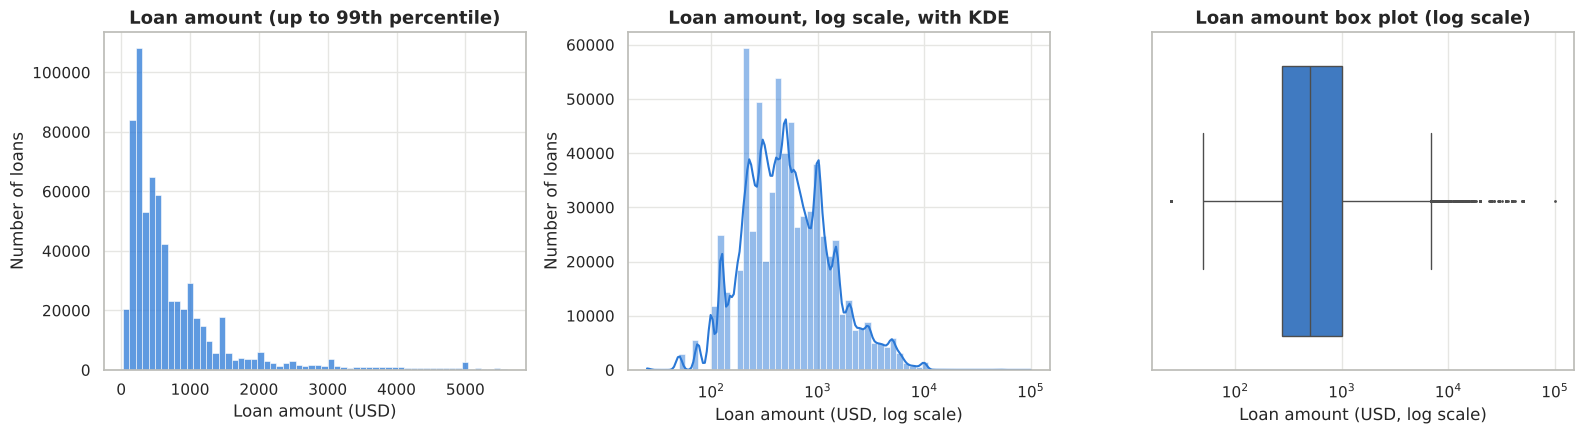

count          671,203.00
mean               842.39
median             500.00
mode               225.00
std_dev          1,198.66
IQR                725.00
min                 25.00
max            100,000.00
skewness             9.80
kurtosis           312.10
IQR_outliers    50,992.00
dtype: float64

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Histogram on the normal scale, cut at the 99th percentile so the bulk is visible
p99 = df["loan_amount"].quantile(0.99)
sns.histplot(df.loc[df["loan_amount"] <= p99, "loan_amount"], bins=60, color=BLUE, ax=axes[0])
axes[0].set_title("Loan amount (up to 99th percentile)")
axes[0].set_xlabel("Loan amount (USD)"); axes[0].set_ylabel("Number of loans")

# (b) Histogram + KDE on a log scale, showing ALL loans
sns.histplot(df["loan_amount"], bins=60, log_scale=True, kde=True, color=BLUE, ax=axes[1])
axes[1].set_title("Loan amount, log scale, with KDE")
axes[1].set_xlabel("Loan amount (USD, log scale)"); axes[1].set_ylabel("Number of loans")

# (c) Box plot on a log scale
sns.boxplot(x=df["loan_amount"], log_scale=True, color=BLUE, fliersize=1, ax=axes[2])
axes[2].set_title("Loan amount box plot (log scale)")
axes[2].set_xlabel("Loan amount (USD, log scale)")
plt.tight_layout(); plt.show()

numeric_summary(df["loan_amount"])

In [21]:
# Spikes at round numbers? The 10 most common loan amounts and their share of all loans
top_amounts = df["loan_amount"].value_counts().head(10)
(top_amounts / len(df) * 100).rename("% of loans").to_frame()

,% of loans
loan_amount,
225.00,4.94
300.00,4.52
500.00,4.33
200.00,3.91
250.00,3.81
125.00,3.71
400.00,3.59
350.00,3.26
325.00,3.00


**Insight — C1: loan_amount**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Shape: right-skewed? (skewness value)
> - Mean vs median: how far apart, and what does that say?
> - Spikes at round numbers like $500 and $1,000 — what share of loans do the top 10 amounts cover? Why might borrowers or partners pick round numbers?
> - Which group of borrowers would you guess is behind the very large loans? (Test it in Section D.)

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### C2. Numeric supporting column — `term_in_months`
**Question:** How long are microloans usually repaid over, and are there unusual terms?

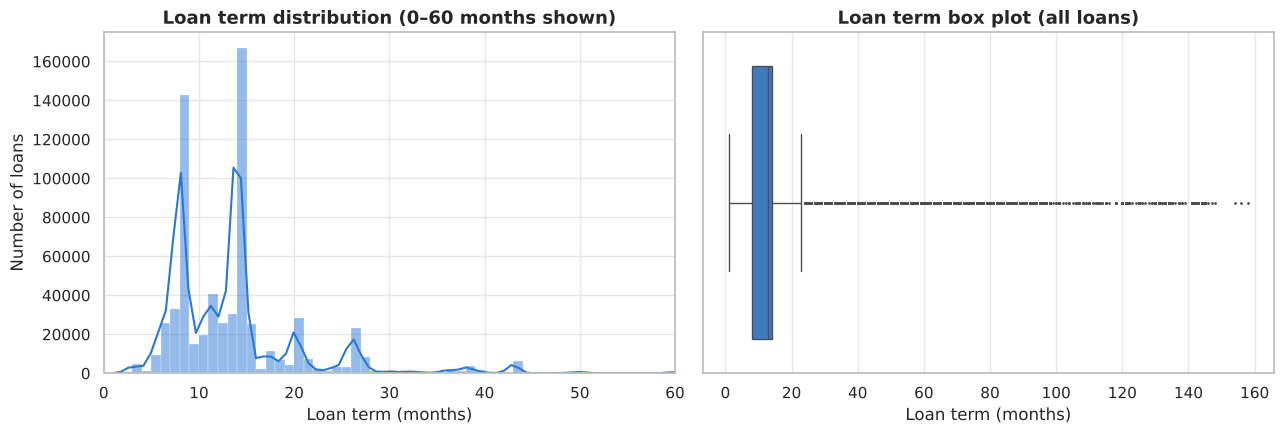

count          671,203.00
mean                13.74
median              13.00
mode                14.00
std_dev              8.60
IQR                  6.00
min                  1.00
max                158.00
skewness             3.73
kurtosis            25.75
IQR_outliers    65,780.00
dtype: float64

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["term_in_months"], binwidth=1, kde=True, color=BLUE, ax=axes[0])
axes[0].set_xlim(0, 60)
axes[0].set_title("Loan term distribution (0–60 months shown)")
axes[0].set_xlabel("Loan term (months)"); axes[0].set_ylabel("Number of loans")

sns.boxplot(x=df["term_in_months"], color=BLUE, fliersize=1, ax=axes[1])
axes[1].set_title("Loan term box plot (all loans)")
axes[1].set_xlabel("Loan term (months)")
plt.tight_layout(); plt.show()

numeric_summary(df["term_in_months"])

In [23]:
# Most common loan terms
(df["term_in_months"].value_counts().head(8) / len(df) * 100).rename("% of loans").to_frame()

,% of loans
term_in_months,
14.00,24.84
8.00,21.31
11.00,6.06
7.00,4.89
13.00,4.54
20.00,4.24
6.00,3.88
12.00,3.83


**Insight — C2: term_in_months**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Is the distribution symmetric or are there clear peaks (e.g. at 8, 14 months)? Peaks suggest standard loan products set by partners.
> - Mean vs median, IQR, kurtosis — is it very concentrated?
> - Are terms above 60 months genuine (e.g. housing loans)? Check in Section D/E.

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### C3. Numeric supporting column — `lender_count`
**Question:** How many lenders does a typical loan need, and how unequal is that across loans?

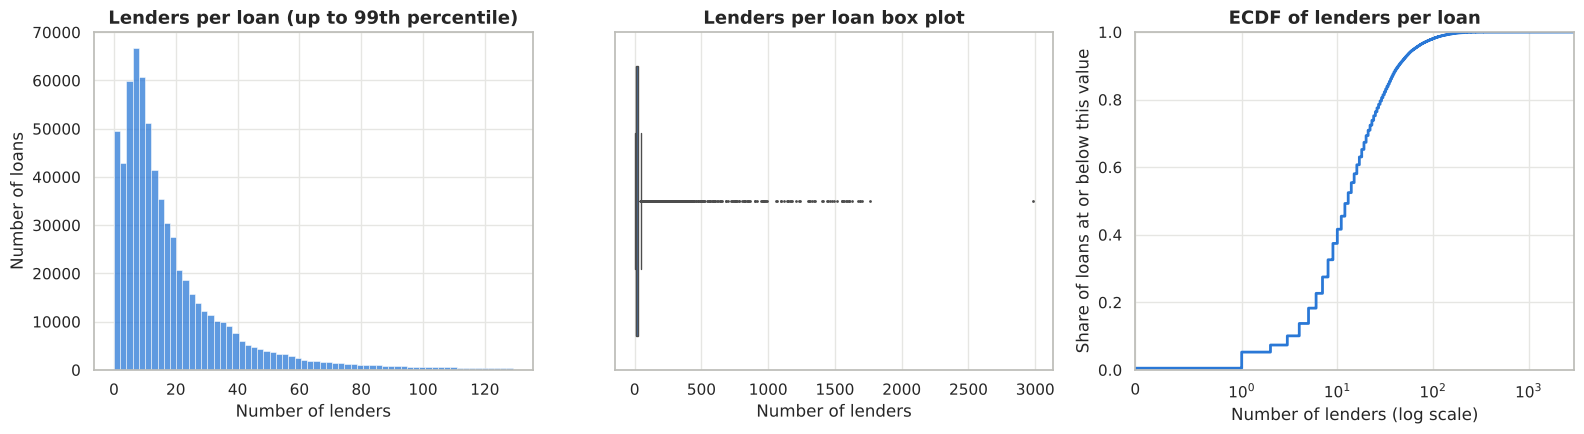

Loans with ZERO lenders: 3383


count          671,203.00
mean                20.59
median              13.00
mode                 8.00
std_dev             28.46
IQR                 17.00
min                  0.00
max              2,986.00
skewness            13.80
kurtosis           634.09
IQR_outliers    54,127.00
dtype: float64

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df.loc[df["lender_count"] <= df["lender_count"].quantile(0.99), "lender_count"],
             binwidth=2, color=BLUE, ax=axes[0])
axes[0].set_title("Lenders per loan (up to 99th percentile)")
axes[0].set_xlabel("Number of lenders"); axes[0].set_ylabel("Number of loans")

sns.boxplot(x=df["lender_count"], color=BLUE, fliersize=1, ax=axes[1])
axes[1].set_title("Lenders per loan box plot")
axes[1].set_xlabel("Number of lenders")

sns.ecdfplot(df["lender_count"], color=BLUE, ax=axes[2], linewidth=2)
axes[2].set_xscale("symlog", linthresh=1)   # log-like scale that can still show 0
axes[2].set_xlim(0, df["lender_count"].max())
axes[2].set_title("ECDF of lenders per loan")
axes[2].set_xlabel("Number of lenders (log scale)"); axes[2].set_ylabel("Share of loans at or below this value")
plt.tight_layout(); plt.show()

print("Loans with ZERO lenders:", (df["lender_count"] == 0).sum())
numeric_summary(df["lender_count"])

**Insight — C3: lender_count**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Read the ECDF: what share of loans need 20 lenders or fewer?
> - Loans with zero lenders — what do they tell you (link to fully_funded)?
> - Because each lender gives about $25, lender_count should follow loan_amount closely — test in D1.

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### C4. Categorical supporting column — `sector`
**Question:** Which sectors receive the most microloans, and is the portfolio dominated by a few sectors?

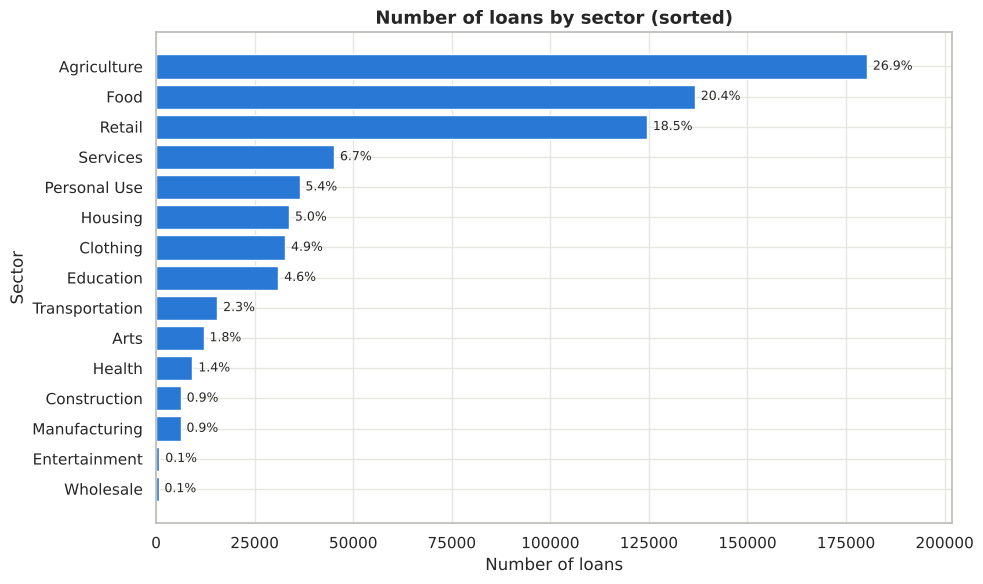

Number of levels: 15 | Dominant level: Agriculture (26.9%)
Top 3 sectors together: 65.8%


,loans,%
sector,,
Agriculture,180301,26.86
Food,136657,20.36
Retail,124493,18.55
Services,45140,6.73
Personal Use,36385,5.42
Housing,33731,5.03
Clothing,32742,4.88
Education,31013,4.62
Transportation,15518,2.31


In [25]:
counts = df["sector"].value_counts()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(counts.index, counts.values, color=BLUE)
ax.invert_yaxis()
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(c + 1500, i, f"{p:.1f}%", va="center", fontsize=9)     # % label on each bar
ax.set_title("Number of loans by sector (sorted)")
ax.set_xlabel("Number of loans"); ax.set_ylabel("Sector")
ax.set_xlim(0, counts.max() * 1.12)
plt.tight_layout(); plt.show()

print("Number of levels:", counts.size, "| Dominant level:", counts.index[0], f"({pct.iloc[0]:.1f}%)")
print("Top 3 sectors together:", f"{pct.head(3).sum():.1f}%")
pd.DataFrame({"loans": counts, "%": pct.round(2)})

**Insight — C4: sector**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Which sector dominates, and what share do the top 3 hold?
> - Which sectors are rare (under 1%)? Should they be treated carefully in group comparisons?
> - Does a portfolio heavy in Agriculture/Food/Retail tell you anything about who Kiva serves?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### C5. `repayment_interval` (optional)
**Question:** How are microloans repaid — monthly, irregularly, in one lump sum (bullet) or weekly?

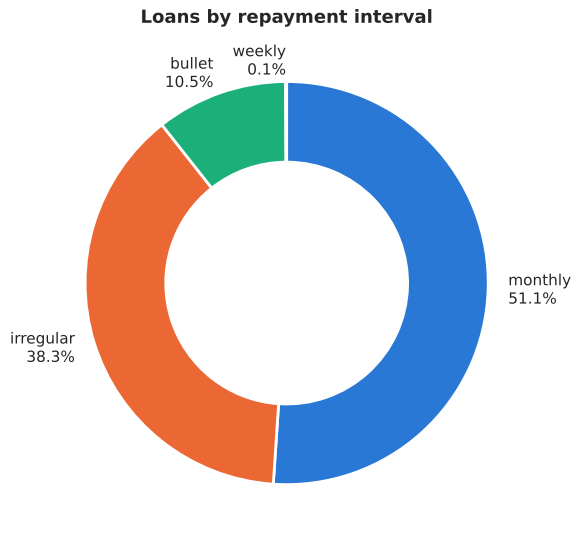

,% of loans
repayment_interval,
monthly,51.06
irregular,38.31
bullet,10.54
weekly,0.09


In [26]:
rep = df["repayment_interval"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(rep.values, labels=[f"{k}\n{v / rep.sum() * 100:.1f}%" for k, v in rep.items()],
       colors=PALETTE[:len(rep)], startangle=90, counterclock=False,
       wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2})    # width<1 makes it a donut
ax.set_title("Loans by repayment interval")
plt.tight_layout(); plt.show()
(rep / rep.sum() * 100).round(2).rename("% of loans").to_frame()

**Insight — C5: repayment_interval**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - How big is 'irregular'? Irregular repayment usually matches seasonal or informal income (e.g. farming).
> - Weekly is tiny — is it worth analysing separately?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### C6. `gender_group` (optional)
**Question:** Who are Kiva's borrowers by gender?

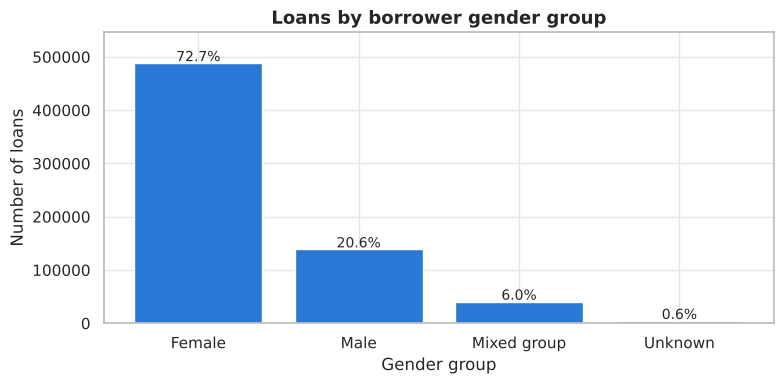

,% of loans
gender_group,
Female,72.72
Male,20.64
Mixed group,6.02
Unknown,0.63


In [27]:
g = df["gender_group"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(g.index, g.values, color=BLUE)
for i, v in enumerate(g.values):
    ax.text(i, v + 4000, f"{v / g.sum() * 100:.1f}%", ha="center", fontsize=10)
ax.set_title("Loans by borrower gender group")
ax.set_xlabel("Gender group"); ax.set_ylabel("Number of loans")
ax.set_ylim(0, g.max() * 1.12)
plt.tight_layout(); plt.show()
(g / g.sum() * 100).round(2).rename("% of loans").to_frame()

**Insight — C6: gender_group**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - How dominant are women borrowers? Is the data balanced?
> - What does this imbalance mean when you compare averages between genders later?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### C-final. Univariate summary
> ✍️ *4–6 bullets: one per variable, each with a number. Example shape: "loan_amount is strongly right-skewed (skew = …): median \$… but mean \$…".*

-
-
-
-

# Section D — Bivariate analysis

### D1. Numeric × Numeric — `loan_amount` vs `lender_count` (and all numeric columns)
**Question:** Do larger loans attract more lenders, and how do all the numeric columns relate to loan_amount?

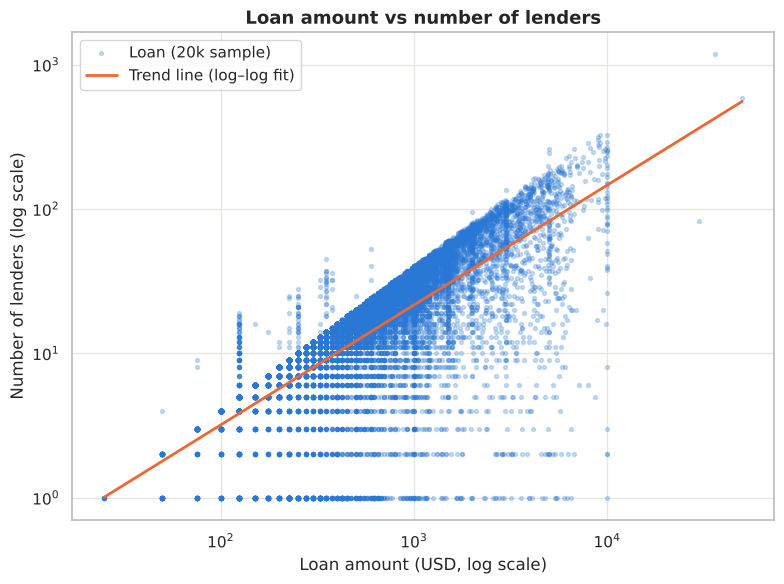

Pearson r  = 0.799 (p = 0)
Spearman ρ = 0.790 (p = 0)


In [28]:
# Scatter on a random sample of 20,000 loans (plotting all 671k points would be one solid blob)
sample = df.sample(20000, random_state=RANDOM_STATE)
sample = sample[sample["lender_count"] > 0]          # log scale cannot show 0

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(sample["loan_amount"], sample["lender_count"], s=8, alpha=0.25, color=BLUE, label="Loan (20k sample)")
# Trend line fitted on log values
b, a = np.polyfit(np.log10(sample["loan_amount"]), np.log10(sample["lender_count"]), 1)
x = np.logspace(np.log10(sample["loan_amount"].min()), np.log10(sample["loan_amount"].max()), 100)
ax.plot(x, 10 ** a * x ** b, color=PALETTE[1], linewidth=2, label="Trend line (log–log fit)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Loan amount vs number of lenders")
ax.set_xlabel("Loan amount (USD, log scale)"); ax.set_ylabel("Number of lenders (log scale)")
ax.legend()
plt.tight_layout(); plt.show()

# Correlation on the FULL data
pear = stats.pearsonr(df["loan_amount"], df["lender_count"])
spear = stats.spearmanr(df["loan_amount"], df["lender_count"])
print(f"Pearson r  = {pear[0]:.3f} (p = {pear[1]:.3g})")
print(f"Spearman ρ = {spear[0]:.3f} (p = {spear[1]:.3g})")

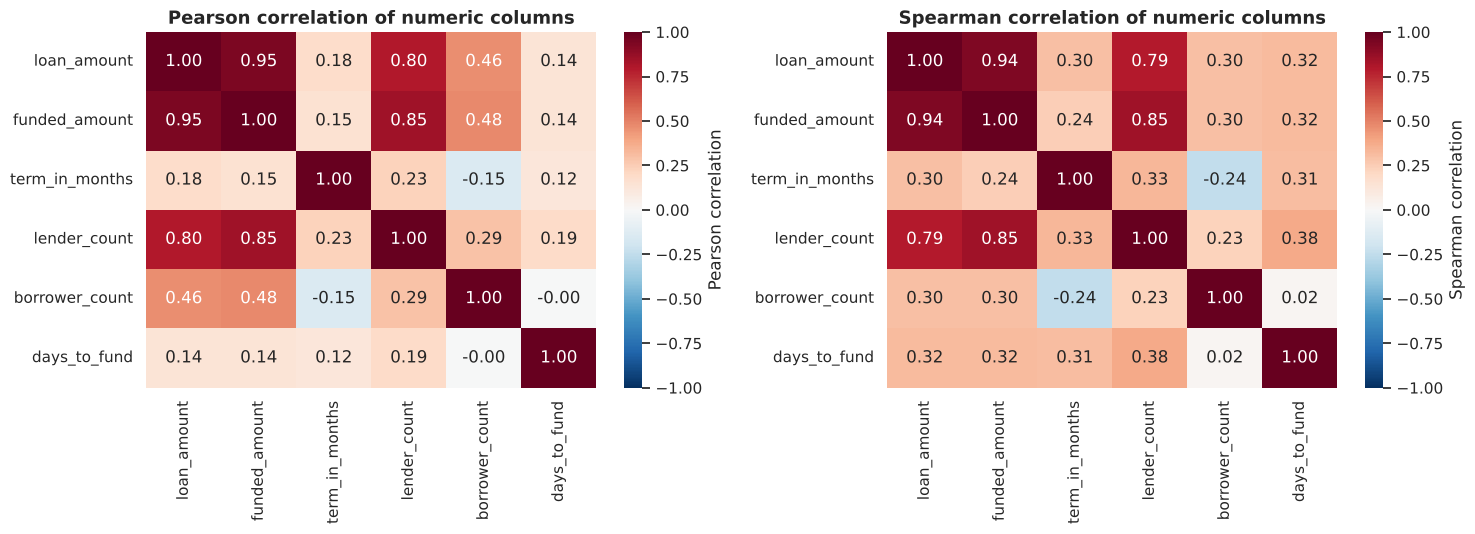

In [29]:
# Correlation heatmap of all numeric columns
num_all = ["loan_amount", "funded_amount", "term_in_months", "lender_count", "borrower_count", "days_to_fund"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[num_all].corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                ax=ax, cbar_kws={"label": f"{method.title()} correlation"})
    ax.set_title(f"{method.title()} correlation of numeric columns")
plt.tight_layout(); plt.show()

**Insight — D1: loan_amount vs lender_count (+ heatmap)**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Direction, strength (r and ρ) and form — is it close to a straight line on the log-log chart?
> - Why might Pearson and Spearman differ? (Hint: outliers and skew.)
> - In the heatmap, which numeric column is most / least related to loan_amount? Is days_to_fund related at all?
> - funded_amount ≈ loan_amount (the leakage point from A5).

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### D2. Categorical × Categorical — `loan_band` vs `gender_group`
**Question:** Do men, women and mixed groups take different sizes of loan?

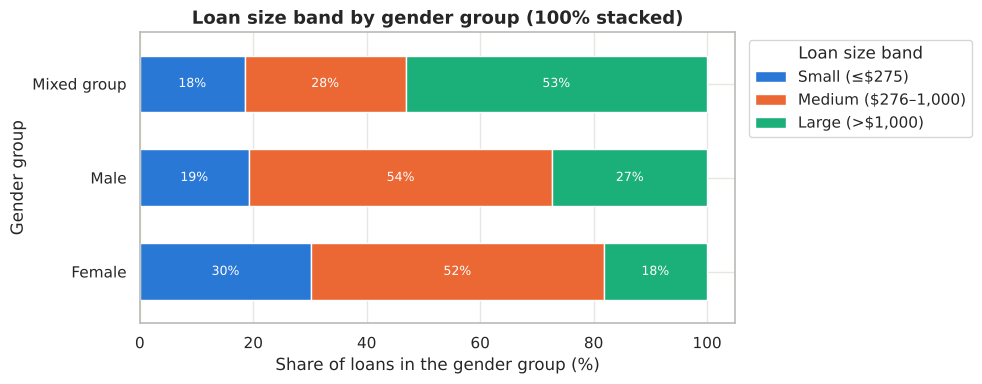

Chi-square = 32,697, dof = 4, p-value = 0, Cramér's V = 0.157


loan_band,Small (≤$275),"Medium ($276–1,000)","Large (>$1,000)"
gender_group,,,
Female,30.20,51.50,18.30
Male,19.20,53.50,27.30
Mixed group,18.50,28.30,53.20


In [30]:
d2 = df[df["gender_group"] != "Unknown"]            # leave out the Unknown group for a clean comparison
ct = pd.crosstab(d2["gender_group"], d2["loan_band"])
ct_pct = pd.crosstab(d2["gender_group"], d2["loan_band"], normalize="index") * 100   # row %

ax = ct_pct.plot(kind="barh", stacked=True, figsize=(10, 4), color=PALETTE[:3], width=0.6, edgecolor="white")
for container in ax.containers:                                # % labels inside each segment
    ax.bar_label(container, fmt="%.0f%%", label_type="center", fontsize=9, color="white")
ax.set_title("Loan size band by gender group (100% stacked)")
ax.set_xlabel("Share of loans in the gender group (%)"); ax.set_ylabel("Gender group")
ax.legend(title="Loan size band", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))   # strength of association, 0–1
print(f"Chi-square = {chi2:,.0f}, dof = {dof}, p-value = {p:.3g}, Cramér's V = {cramers_v:.3f}")
ct_pct.round(1)

**Insight — D2: loan_band × gender_group**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - What % of women's loans are Large vs men's? What about Mixed groups?
> - The p-value is tiny because the data is huge — use Cramér's V (0 = no link, 1 = perfect) to judge whether the link is big enough to matter.
> - Could a third variable (sector? country?) explain the gender gap? Test in E3.

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### D3. Numeric × Categorical — `loan_amount` across `sector`
**Question:** Which sectors take the largest and smallest loans?

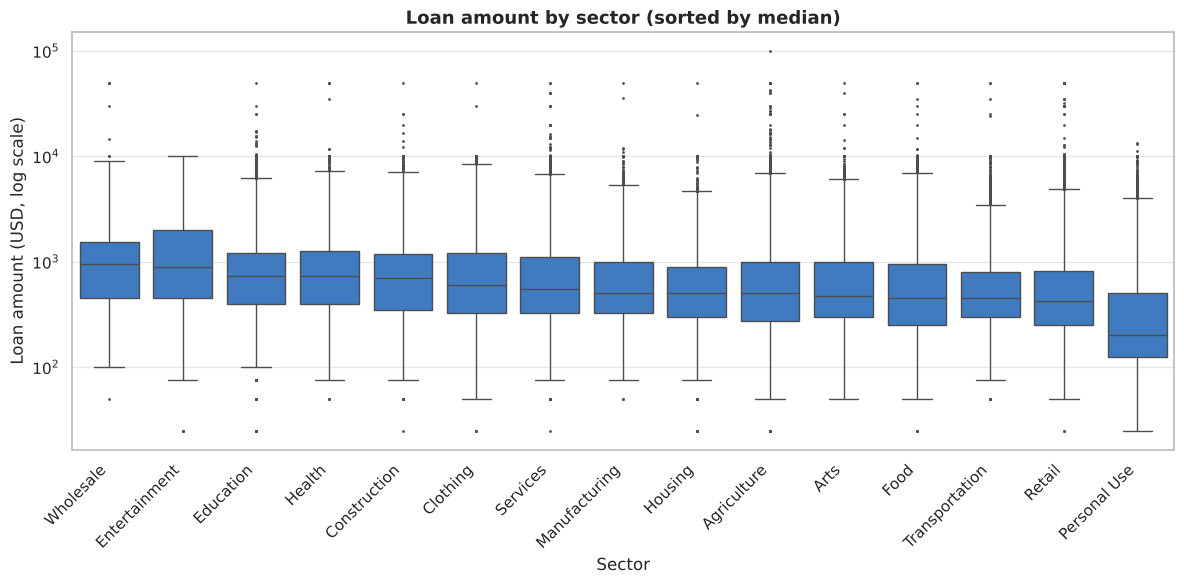

ANOVA F = 846.7, p = 0 | Kruskal-Wallis H = 35,410, p = 0 | eta² = 0.017


,count,mean,median
sector,,,
Wholesale,634,"1,569.72",950.00
Entertainment,830,"1,673.67",887.50
Education,31013,998.57,725.00
Health,9223,"1,067.27",725.00
Construction,6268,"1,068.15",700.00
Clothing,32742,"1,139.24",600.00
Services,45140,"1,064.63",550.00
Manufacturing,6208,877.56,500.00
Housing,33731,701.55,500.00


In [31]:
order = df.groupby("sector")["loan_amount"].median().sort_values(ascending=False).index   # sort by median

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df, x="sector", y="loan_amount", order=order, color=BLUE, fliersize=1, log_scale=True, ax=ax)
ax.set_title("Loan amount by sector (sorted by median)")
ax.set_xlabel("Sector"); ax.set_ylabel("Loan amount (USD, log scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

# Group statistics
grp = df.groupby("sector")["loan_amount"].agg(["count", "mean", "median"]).loc[order]

# One-way ANOVA (compares means) and Kruskal-Wallis (compares medians, better for skewed data)
groups = [g["loan_amount"].values for _, g in df.groupby("sector")]
f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)
# Eta squared = share of loan_amount variation explained by sector (0–1)
grand = df["loan_amount"].mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df["loan_amount"] - grand) ** 2).sum()
print(f"ANOVA F = {f_stat:,.1f}, p = {p_anova:.3g} | Kruskal-Wallis H = {h_stat:,.0f}, p = {p_kw:.3g} | eta² = {eta2:.3f}")
grp

**Insight — D3: loan_amount × sector**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Which sector has the highest and lowest median loan? How many times bigger?
> - Mean vs median by sector — which sectors have a few huge loans pulling the mean up?
> - Eta² tells you how much of the loan-size differences sector explains. Is it a lot?
> - Does this confirm or reject expectation E1?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### D4. Numeric × Categorical — `loan_amount` across `gender_group`
**Question:** Do women borrow less than men, and is the difference big enough to matter?

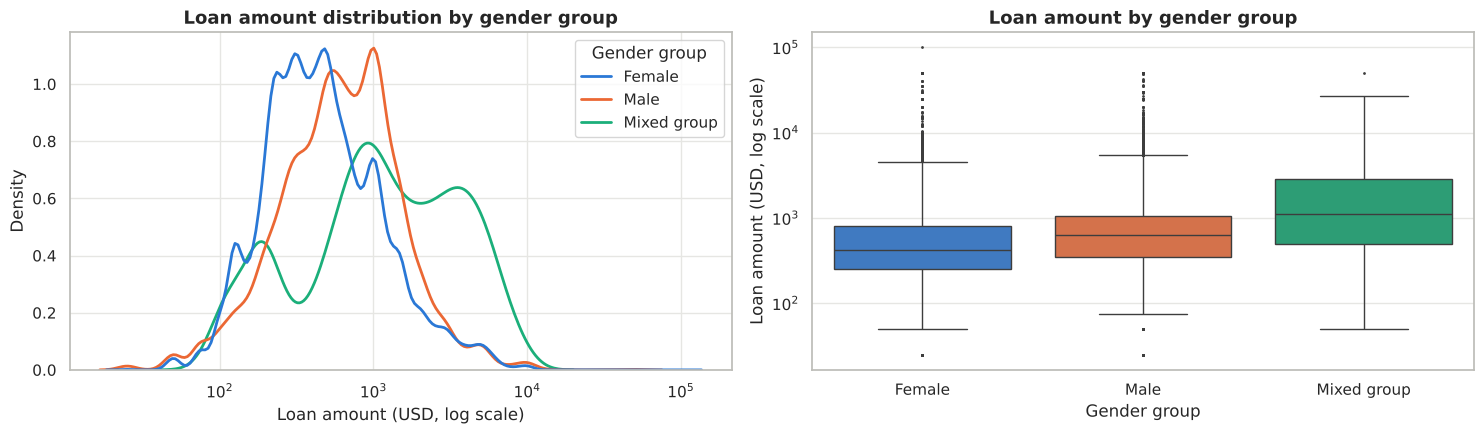

Welch t-test (Female vs Male): t = -48.6, p = 0
Mann-Whitney U (Female vs Male): p = 0


,count,mean,median
gender_group,,,
Female,488081,730.49,425.00
Male,138521,916.25,625.00
Mixed group,40380,"1,907.06","1,100.00"


In [32]:
d4 = df[df["gender_group"] != "Unknown"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.kdeplot(data=d4.sample(60000, random_state=RANDOM_STATE), x="loan_amount", hue="gender_group",
            hue_order=["Female", "Male", "Mixed group"], log_scale=True, common_norm=False,
            palette=PALETTE[:3], linewidth=2, ax=axes[0])
axes[0].set_title("Loan amount distribution by gender group")
axes[0].set_xlabel("Loan amount (USD, log scale)"); axes[0].set_ylabel("Density")
axes[0].get_legend().set_title("Gender group")

sns.boxplot(data=d4, x="gender_group", y="loan_amount", order=["Female", "Male", "Mixed group"],
            hue="gender_group", palette=PALETTE[:3], fliersize=1, log_scale=True, legend=False, ax=axes[1])
axes[1].set_title("Loan amount by gender group")
axes[1].set_xlabel("Gender group"); axes[1].set_ylabel("Loan amount (USD, log scale)")
plt.tight_layout(); plt.show()

female = d4.loc[d4["gender_group"] == "Female", "loan_amount"]
male = d4.loc[d4["gender_group"] == "Male", "loan_amount"]
t, p_t = stats.ttest_ind(female, male, equal_var=False)       # Welch t-test (unequal variances)
u, p_u = stats.mannwhitneyu(female, male)                     # rank-based test, fine for skewed data
print(f"Welch t-test (Female vs Male): t = {t:.1f}, p = {p_t:.3g}")
print(f"Mann-Whitney U (Female vs Male): p = {p_u:.3g}")
d4.groupby("gender_group")["loan_amount"].agg(["count", "mean", "median"])

In [33]:
# Single women vs single men only (borrower_count == 1) — removes the effect of group size
solo = d4[d4["borrower_count"] == 1]
solo.groupby("gender_group")["loan_amount"].agg(["count", "mean", "median"])

,count,mean,median
gender_group,,,
Female,426502,593.09,400.00
Male,134708,899.03,600.00


**Insight — D4: loan_amount × gender_group**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Median loan for women vs men — how big is the gap in dollars and %?
> - Mixed groups are much bigger — is that because they are groups (more borrowers), not because of gender?
> - Compare with the single-borrower table: does the gap shrink, stay or reverse? (Possible confounder: borrower_count.)
> - Does this support expectation E2?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### D5. Over time (optional) — `loan_amount` by posting month
**Question:** Has the typical loan size changed between 2014 and 2017?

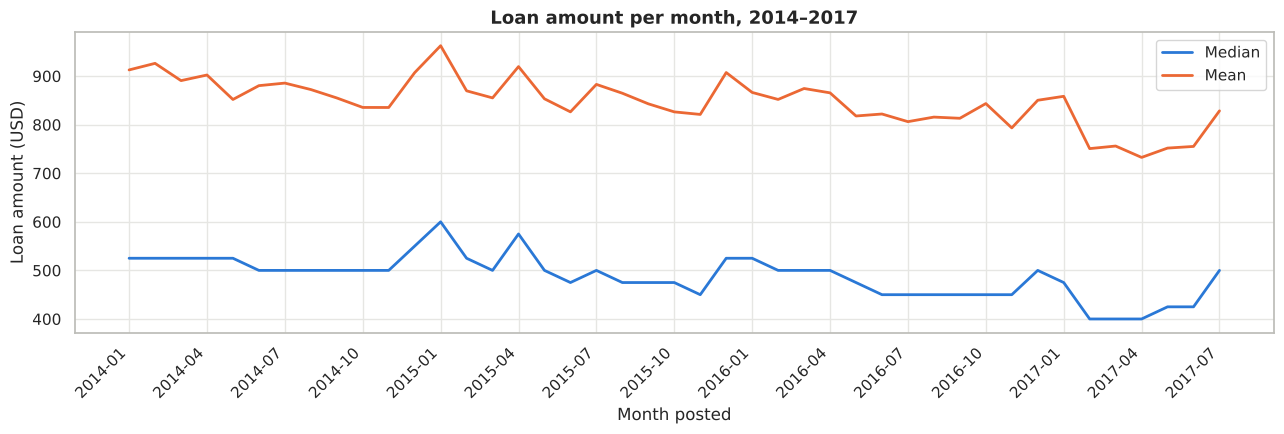

In [34]:
monthly = (df.assign(month=df_raw.loc[df.index, "date"].str[:7])          # take 'YYYY-MM' from the raw date
             .groupby("month")["loan_amount"].agg(["median", "mean", "count"]))
monthly = monthly[monthly["count"] > 1000]                                  # skip months with very few loans

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(monthly.index, monthly["median"], color=BLUE, linewidth=2, label="Median")
ax.plot(monthly.index, monthly["mean"], color=PALETTE[1], linewidth=2, label="Mean")
ax.set_title("Loan amount per month, 2014–2017")
ax.set_xlabel("Month posted"); ax.set_ylabel("Loan amount (USD)")
ax.set_xticks(monthly.index[::3]); plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout(); plt.show()

**Insight — D5: loan_amount over time**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Is there a trend, seasonality or a sudden jump?
> - Why is the mean always above the median?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### D-final. Bivariate summary — ranking the drivers of `loan_amount`
The table below puts every supporting column on a comparable 0–1 strength scale: **Spearman ρ²** for numeric columns and **eta²** for categorical columns (both = share of the variation in loan_amount linked to that column, by rank for ρ²).

In [35]:
rank_loan = df["loan_amount"].rank()     # use ranks so the huge outliers don't dominate
rows = []
for col in ["lender_count", "term_in_months", "borrower_count", "days_to_fund"]:
    rho = df[["loan_amount", col]].dropna().corr(method="spearman").iloc[0, 1]
    rows.append([col, "numeric", f"Spearman ρ = {rho:.2f}", rho ** 2])
for col in ["sector", "gender_group", "repayment_interval", "country_group"]:
    gm = rank_loan.groupby(df[col]).mean()
    n = df[col].value_counts()
    eta2 = (n * (gm - rank_loan.mean()) ** 2).sum() / ((rank_loan - rank_loan.mean()) ** 2).sum()
    rows.append([col, "categorical", f"eta² (on ranks) = {eta2:.2f}", eta2])
pd.DataFrame(rows, columns=["column", "type", "evidence", "strength_0_to_1"]) \
  .sort_values("strength_0_to_1", ascending=False).reset_index(drop=True)

,column,type,evidence,strength_0_to_1
0,lender_count,numeric,Spearman ρ = 0.79,0.62
1,country_group,categorical,eta² (on ranks) = 0.26,0.26
2,days_to_fund,numeric,Spearman ρ = 0.32,0.10
3,borrower_count,numeric,Spearman ρ = 0.30,0.09
4,term_in_months,numeric,Spearman ρ = 0.30,0.09
5,repayment_interval,categorical,eta² (on ranks) = 0.07,0.07
6,sector,categorical,eta² (on ranks) = 0.05,0.05
7,gender_group,categorical,eta² (on ranks) = 0.04,0.04


> ✍️ *Rank the columns from strongest to weakest, one line of evidence each (use the table above and your D1–D4 numbers).*

1.
2.
3.
4.
5.

# Section E — Multivariate analysis

### E1. 3 Numeric — `loan_amount`, `term_in_months`, `lender_count`
**Question:** Once we account for the number of lenders, is a longer term still linked to a larger loan?

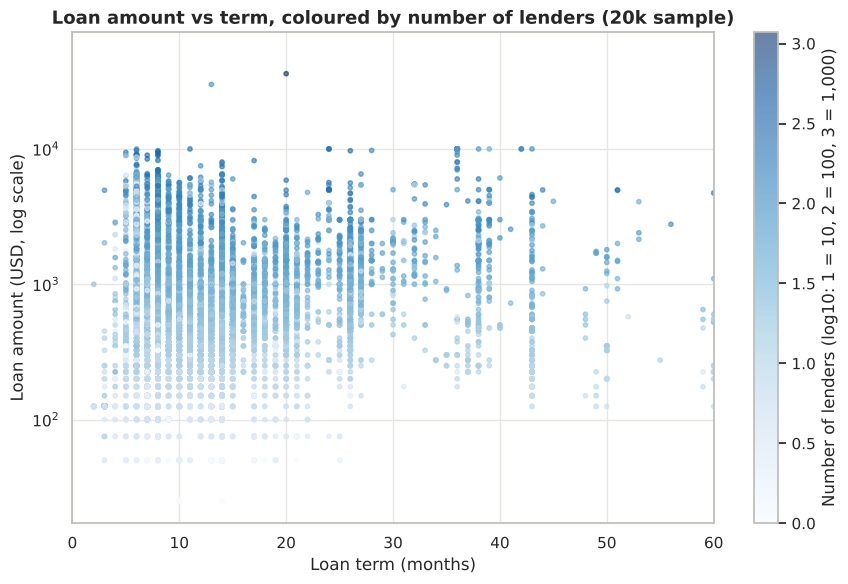

Spearman correlation matrix:


,loan_amount,term_in_months,lender_count
loan_amount,1.00,0.30,0.79
term_in_months,0.30,1.00,0.33
lender_count,0.79,0.33,1.00


Partial correlation (loan_amount vs term | lender_count) = 0.065


In [36]:
s = df.sample(20000, random_state=RANDOM_STATE)
s = s[s["lender_count"] > 0]
fig, ax = plt.subplots(figsize=(9, 6))
pts = ax.scatter(s["term_in_months"], s["loan_amount"], c=np.log10(s["lender_count"]),
                 cmap="Blues", s=10, alpha=0.6, vmin=0)
cbar = plt.colorbar(pts, ax=ax)
cbar.set_label("Number of lenders (log10: 1 = 10, 2 = 100, 3 = 1,000)")
ax.set_yscale("log"); ax.set_xlim(0, 60)
ax.set_title("Loan amount vs term, coloured by number of lenders (20k sample)")
ax.set_xlabel("Loan term (months)"); ax.set_ylabel("Loan amount (USD, log scale)")
plt.tight_layout(); plt.show()

three = ["loan_amount", "term_in_months", "lender_count"]
print("Spearman correlation matrix:")
display(df[three].corr(method="spearman"))

# Partial correlation: loan_amount vs term after removing the effect of lender_count (on ranks)
r = df[three].rank()
def residual(y, x):
    slope, intercept = np.polyfit(x, y, 1)
    return y - (slope * x + intercept)
partial = np.corrcoef(residual(r["loan_amount"], r["lender_count"]),
                      residual(r["term_in_months"], r["lender_count"]))[0, 1]
print(f"Partial correlation (loan_amount vs term | lender_count) = {partial:.3f}")

**Insight — E1: loan_amount × term × lender_count**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Compare the simple correlation of loan_amount with term vs the partial correlation — does the link get weaker, stronger or change sign once lenders are controlled for?
> - Where are the dark (many-lender) points on the chart?
> - What would a manager miss by only looking at loan_amount vs term?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### E2. 2 Numeric + 1 Categorical — `loan_amount` vs `term_in_months` by `repayment_interval`
**Question:** Does the link between loan term and loan size depend on how the loan is repaid?

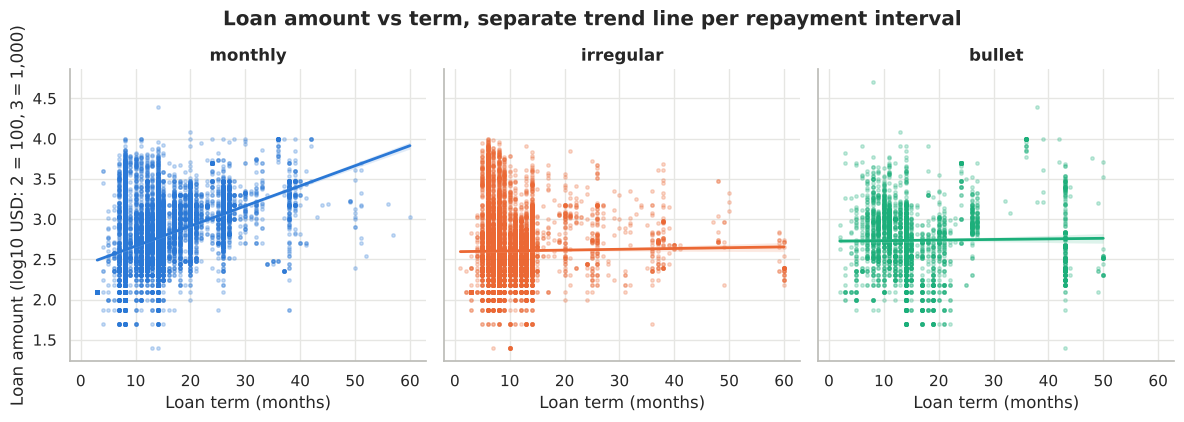

,n,share_%,spearman_term_vs_loan,median_loan
repayment_interval,,,,
monthly,"342,715.00",51.06,0.40,600.00
irregular,"257,158.00",38.31,0.01,350.00
bullet,"70,728.00",10.54,-0.12,575.00
weekly,602.00,0.09,0.91,237.50


In [37]:
e2 = df[df["repayment_interval"] != "weekly"].sample(30000, random_state=RANDOM_STATE).copy()
e2["log10_loan_amount"] = np.log10(e2["loan_amount"])        # log so the trend line is readable
e2 = e2[e2["term_in_months"] <= 60]
rep_order = ["monthly", "irregular", "bullet", "weekly"]
plot_order = rep_order[:3]     # weekly is only 0.09% of loans (~20 points in the sample), so it is left out of the chart
g = sns.lmplot(data=e2, x="term_in_months", y="log10_loan_amount", col="repayment_interval", col_order=plot_order,
               hue="repayment_interval", hue_order=plot_order, palette=PALETTE[:3], height=4, aspect=1,
               scatter_kws={"s": 6, "alpha": 0.25}, line_kws={"linewidth": 2}, legend=True)
g.set_axis_labels("Loan term (months)", "Loan amount (log10 USD: 2 = $100, 3 = $1,000)")
g.set_titles("{col_name}")
g.fig.suptitle("Loan amount vs term, separate trend line per repayment interval", y=1.05, fontweight="bold")
plt.show()

# Correlation of the two numeric columns within each repayment interval (full data)
within = df.groupby("repayment_interval").apply(
    lambda x: pd.Series({"n": len(x), "share_%": len(x) / len(df) * 100,
                         "spearman_term_vs_loan": x["term_in_months"].corr(x["loan_amount"], method="spearman"),
                         "median_loan": x["loan_amount"].median()}))
within.loc[rep_order]

**Insight — E2: loan_amount × term × repayment_interval**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Is the term–loan link the same in every repayment group, or does it flip / vanish in one (interaction)?
> - Overall correlation (D1 heatmap) vs within-group correlations — any Simpson's paradox?
> - Which repayment type has the largest median loan? Does that support E3?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### E3. 1 Numeric + 2 Categorical — `loan_amount` by `sector` × `gender_group`
**Question:** Is the gender gap in loan size the same in every sector, or is it really a sector effect?

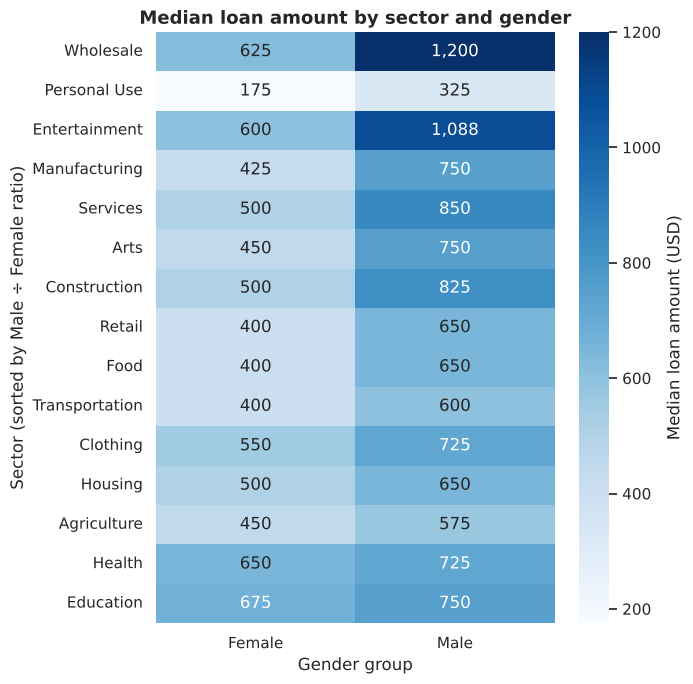

Median loan (USD) and Male ÷ Female ratio:


gender_group,Female,Male,Male ÷ Female
sector,,,
Wholesale,625.00,"1,200.00",1.92
Personal Use,175.00,325.00,1.86
Entertainment,600.00,"1,087.50",1.81
Manufacturing,425.00,750.00,1.76
Services,500.00,850.00,1.70
Arts,450.00,750.00,1.67
Construction,500.00,825.00,1.65
Retail,400.00,650.00,1.62
Food,400.00,650.00,1.62


Number of loans in each cell:


gender_group,Female,Male
sector,,
Wholesale,344,268
Personal Use,18741,8667
Entertainment,402,396
Manufacturing,3612,2359
Services,33434,10187
Arts,10349,1236
Construction,2769,3147
Retail,105201,14513
Food,113414,14689


In [38]:
e3 = df[df["gender_group"].isin(["Female", "Male"])]
med = pd.pivot_table(e3, values="loan_amount", index="sector", columns="gender_group", aggfunc="median")
cnt = pd.pivot_table(e3, values="loan_amount", index="sector", columns="gender_group", aggfunc="count")
med["Male ÷ Female"] = med["Male"] / med["Female"]           # how many times larger men's median loan is
med = med.sort_values("Male ÷ Female", ascending=False)

fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(med[["Female", "Male"]], annot=True, fmt=",.0f", cmap="Blues", ax=ax,
            cbar_kws={"label": "Median loan amount (USD)"})
ax.set_title("Median loan amount by sector and gender")
ax.set_xlabel("Gender group"); ax.set_ylabel("Sector (sorted by Male ÷ Female ratio)")
plt.tight_layout(); plt.show()

print("Median loan (USD) and Male ÷ Female ratio:")
display(med.round(2))
print("Number of loans in each cell:")
display(cnt.loc[med.index])

**Insight — E3: loan_amount × sector × gender_group**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - In which sectors do men get much bigger loans, and are there sectors where women's median is equal or higher?
> - Is the overall gap from D4 smaller or bigger inside sectors? If smaller, part of the 'gender gap' is a sector-mix effect.
> - Check the counts table — some Male cells are small, so be careful with them.
> - Name the best and worst segment with its count and %.

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### E4. 1 Numeric + 2 Categorical (optional) — `loan_amount` by `country_group` × `repayment_interval`
**Question:** Do repayment structures carry different loan sizes in different countries?

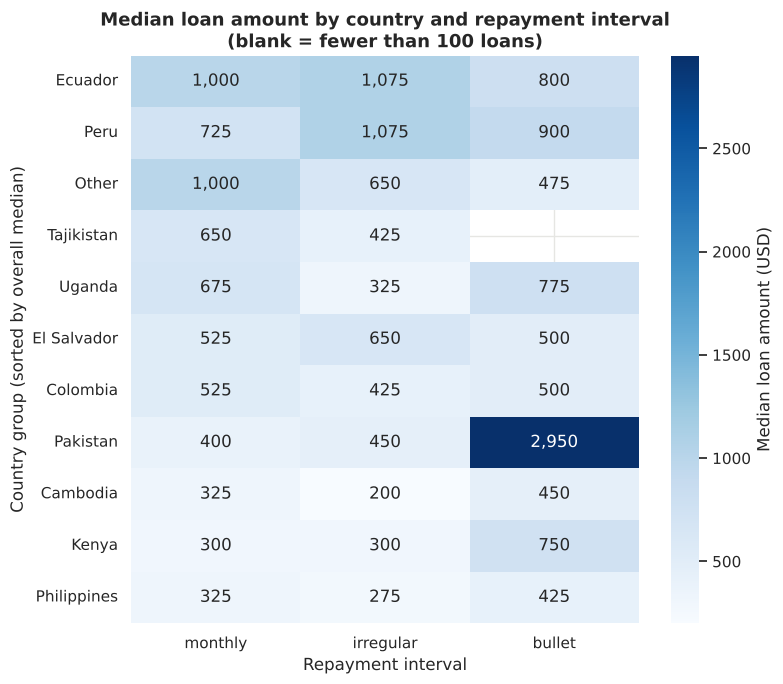

repayment_interval,monthly,irregular,bullet
country_group,,,
Ecuador,"6,735.00","5,558.00","1,228.00"
Peru,"12,043.00","7,455.00","2,735.00"
Other,"138,553.00","63,852.00","33,034.00"
Tajikistan,"19,417.00",158.00,5.00
Uganda,"13,211.00","7,260.00",130.00
El Salvador,"29,764.00","1,926.00","8,185.00"
Colombia,"8,061.00",149.00,"13,785.00"
Pakistan,"20,556.00","6,200.00",101.00
Cambodia,"34,406.00",220.00,210.00


In [39]:
e4_med = pd.pivot_table(df, values="loan_amount", index="country_group", columns="repayment_interval",
                        aggfunc="median")[["monthly", "irregular", "bullet"]]
e4_cnt = pd.pivot_table(df, values="loan_amount", index="country_group", columns="repayment_interval",
                        aggfunc="count")[["monthly", "irregular", "bullet"]]
e4_med = e4_med.where(e4_cnt >= 100)        # hide cells with fewer than 100 loans (too few to trust)
e4_med = e4_med.loc[df.groupby("country_group")["loan_amount"].median().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(e4_med, annot=True, fmt=",.0f", cmap="Blues", ax=ax, cbar_kws={"label": "Median loan amount (USD)"})
ax.set_title("Median loan amount by country and repayment interval\n(blank = fewer than 100 loans)")
ax.set_xlabel("Repayment interval"); ax.set_ylabel("Country group (sorted by overall median)")
plt.tight_layout(); plt.show()
display(e4_cnt.loc[e4_med.index])

**Insight — E4: loan_amount × country_group × repayment_interval**

> ✍️ *Write this in your own words, 80–150 words, then delete this grey hint box. Look at:*
> - Which countries have the largest and smallest loans?
> - Within a country, is bullet always bigger than monthly? Or does it depend on the country (interaction)?
> - Is the repayment-interval effect from E2 really a country effect?

- **Observation:**
- **Hidden insight:**
- **Business meaning:**
- **Next step:**

### E-final. Multivariate summary
> ✍️ *Describe the 2–3 most important segments, one line each, with numbers. Example shape: "Male borrowers in the X sector in country Y take a median loan of \$…, N times the overall median of \$… (n = …, …% of loans)."*

1.
2.
3.

# Section F — Consolidated conclusion
> ✍️ *500–800 words in total across F1–F5. Connect the findings, don't just repeat them.*

### F1. Executive summary
-
-
-
-
-

### F2. Expectation scorecard

| # | Expectation | Verdict (confirmed / rejected / partly supported) | Evidence (question, statistic) |
|---|---|---|---|
| E1 | Retail and Services loans are larger than Agriculture and Personal Use loans | | |
| E2 | Loans to women are smaller than loans to men | | |
| E3 | Bullet loans are larger than monthly loans | | |
| E4 | Longer-term loans are larger loans | | |
| E5 | Larger loans need more lenders | | |
| E6 | Larger loans take longer to get fully funded | | |
| E7 | Loan sizes differ a lot between countries | | |

### F3. Key drivers of loan_amount
1.
2.
3.

### F4. Business recommendations
| # | Target segment | Action | Expected impact |
|---|---|---|---|
| 1 | | | |
| 2 | | | |
| 3 | | | |

### F5. Limitations and next steps
-
-
-